# 01 - Inspection des datasets
Place les CSV dans `data/raw/` puis inspecte colonnes, types, valeurs manquantes.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAW = Path('../data/raw')

In [66]:
# Chargeons les fichiers CSV dans des DataFrames pandas
dataframes = {}
for csv_file in RAW.glob('*.csv'):
    df_name = csv_file.stem  # Utilise le nom du fichier sans l'extension comme nom de DataFrame
    dataframes[df_name] = pd.read_csv(csv_file)

print(dataframes.keys())  # Affiche les noms des DataFrames chargés

dict_keys(['ott_subscriber_master_raw', 'Online_sports_DIB', 'Online_casino_DIB'])


In [67]:
# commencons par 'ott_subscriber_master_raw'
# df = dataframes['ott_subscriber_master_raw']

# print(df.shape) 10300(lignes) x 59(colonnes)
# print(df.info())
# print((df.isnull().mean() * 100).sort_values(ascending=False))  # Pourcentage de valeurs manquantes par colonne
'''
    les seules colonnes a avoir des valeurs manquantes en termes de pourcentage sont:
        days_since_last_activity        3.883495
        satisfaction_score              3.689320
        age                             3.495146
        avg_session_duration_mins       3.300971
'''

'\n    les seules colonnes a avoir des valeurs manquantes en termes de pourcentage sont:\n        days_since_last_activity        3.883495\n        satisfaction_score              3.689320\n        age                             3.495146\n        avg_session_duration_mins       3.300971\n'

In [68]:
# commencons par 'Online_sports_DIB'
df_sports = dataframes['Online_sports_DIB']

# print(df.shape) #447853(lignes) x 5(colonnes)
# print(df.info())
# print((df.isnull().mean() * 100).sort_values(ascending=False))  # Pourcentage de valeurs manquantes par colonne
'''
    la seule colonne a avoir des valeurs manquantes en termes de pourcentage est:
        Status               0.00134
'''

'\n    la seule colonne a avoir des valeurs manquantes en termes de pourcentage est:\n        Status               0.00134\n'

In [69]:
# commencons par 'Online_casino_DIB'
df_casino = dataframes['Online_casino_DIB']

# print(df.shape) #138928(lignes) x 5(colonnes)
# print(df.info())
# print((df.isnull().mean() * 100).sort_values(ascending=False))  # Pourcentage de valeurs manquantes par colonne


## FILTRAGE METIER

#### Objectif : Nettoyer ott_subscriber_master_raw.csv en gardant uniquement les variables liées au jeu d'argent, au comportement et au marketing (et supprimer tout ce qui concerne le streaming vidéo comme titles_watched_per_month ou series_completion_rate).

In [70]:
df = dataframes['ott_subscriber_master_raw']

colonnes_a_garder = [
    # 1. Identité & Profil
    'subscriber_id', 'age', 'gender', 'region', 'primary_device',
    'subscription_tenure_months',
    
    # 2. Comportement de Jeu & Préférences 
    'favourite_sport', 'preferred_bet_type', 'betting_profile',
    'game_genre_preference', 'avg_betting_odds', 'betting_win_rate',
    'responsible_gambling_flag',
    
    # 3. Finances & Valeur Joueur 
    'bets_placed_total', 'avg_bet_amount_eur', 'total_stake_eur',
    'total_gain_eur', 'total_ggr', 'payment_method', 'payment_failures',
    
    # 4. Temporalité & Engagement 
    'days_since_last_activity', 'gaming_sessions_per_week',
    'avg_gaming_session_mins', 'time_on_site_mins', 'peak_viewing_hour',
    
    # 5. Marketing, Acquisition & Rétention 
    'acquisition_channel', 'acquisition_campaign_type', 'ad_spend_eur',
    'ctr', 'conversion_rate', 'roas', 'promo_discount_pct',
    'promo_discount_applied', 'loyalty_points', 'support_tickets_raised',
    'satisfaction_score', 'churn'
]

# Création du DataFrame filtré
df_clean = df[colonnes_a_garder].copy()

print(f"Dimensions après filtrage : {df_clean.shape}")
print("\nColonnes avec valeurs manquantes dans notre sélection :")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])

Dimensions après filtrage : (10300, 37)

Colonnes avec valeurs manquantes dans notre sélection :
age                         360
days_since_last_activity    400
satisfaction_score          380
dtype: int64


## Cellule 3 : Nettoyage des valeurs manquantes, doublons et incohérences
##### Objectif : Garantir qu'aucune valeur NaN ni anomalie ne fasse planter ton futur modèle de Machine Learning.

In [71]:
# suppression des doublons
# print("Doublons dans subscriber_id :", df_clean.duplicated(subset=['subscriber_id']).sum())
# il ya 0 doublon 

# Remplir les valeurs manquantes pour les colonnes numériques avec la médiane
cols_a_nettoyer = ['age', 'days_since_last_activity', 'satisfaction_score']

for col in cols_a_nettoyer:
    mediane = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(mediane)
    
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])


Series([], dtype: int64)


###  CELLULE 4 : ENRICHISSEMENT TRANSACTIONNEL & CONTEXTUALISATION PRIMEBET

In [72]:

# 2. Agréger les montants approuvés par joueur pour Casino et Sports
casino_agg = df_casino[df_casino['Status'] == 'APPROVED'].groupby('AccountIdentifier')['TransactionAmount'].sum()
sports_agg = df_sports[df_sports['Status'] == 'APPROVED'].groupby('AccountIdentifier')['TransactionAmount'].sum()

# Réunir dans un tableau récapitulatif et calculer la part Casino (entre 0 et 1)
tx_summary = pd.DataFrame({'casino_vol': casino_agg, 'sports_vol': sports_agg}).fillna(0)
tx_summary['casino_share_ratio'] = tx_summary['casino_vol'] / (tx_summary['casino_vol'] + tx_summary['sports_vol'] + 1e-5)

# 3. Assigner ces comportements réalistes à nos 10 300 joueurs
sampled_tx = tx_summary.sample(n=len(df_clean), replace=True, random_state=42).reset_index(drop=True)
df_clean['casino_share_ratio'] = sampled_tx['casino_share_ratio'].round(2)

# 4. Contextualisation métier Primebet
df_clean = df_clean.rename(columns={'subscriber_id': 'user_id'})

df_clean['payment_method'] = df_clean['payment_method'].replace({
    'PayPal': 'Mobile Money',
    'Debit Card': 'Mobile Wallet / USSD',
    'Credit Card': 'Bank Card'
})

df_clean['game_genre_preference'] = df_clean['game_genre_preference'].replace({
    'Action': 'Aviator (Crash Game)',
    'Sports': 'Virtual Football',
    'Simulation': 'Live Roulette',
    'Strategy': 'Table Games',
    'RPG': 'Slots & Jackpots'
})

df_clean['region'] = df_clean['region'].replace({
    'LATAM': 'Harare',
    'APAC': 'Bulawayo',
    'AMER': 'Mutare',
    'EMEA': 'Gweru'
})

# Aperçu du résultat final prêt pour la visualisation
display(df_clean[['user_id', 'region', 'payment_method', 'favourite_sport', 'game_genre_preference', 'casino_share_ratio', 'total_ggr', 'churn']].head())

,user_id,region,payment_method,favourite_sport,game_genre_preference,casino_share_ratio,total_ggr,churn
0,SUB-00001,Harare,Mobile Money,Football,Aviator (Crash Game),0.02,88.29,0
1,SUB-00002,Bulawayo,Mobile Wallet / USSD,Football,Aviator (Crash Game),0.01,59.69,0
2,SUB-00003,Bulawayo,Mobile Money,Football,Virtual Football,0.71,-1032.42,0
3,SUB-00004,Mutare,Mobile Wallet / USSD,Football,Aviator (Crash Game),0.01,117.08,1
4,SUB-00005,Bulawayo,Bank Card,Football,Live Roulette,0.00,-519.60,0


### CELLULE 5 : VISUALISATION EXPLORATOIRE (EDA) & SAUVEGARDE 


/tmp/ipykernel_8396/169139927.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_8396/169139927.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_8396/169139927.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


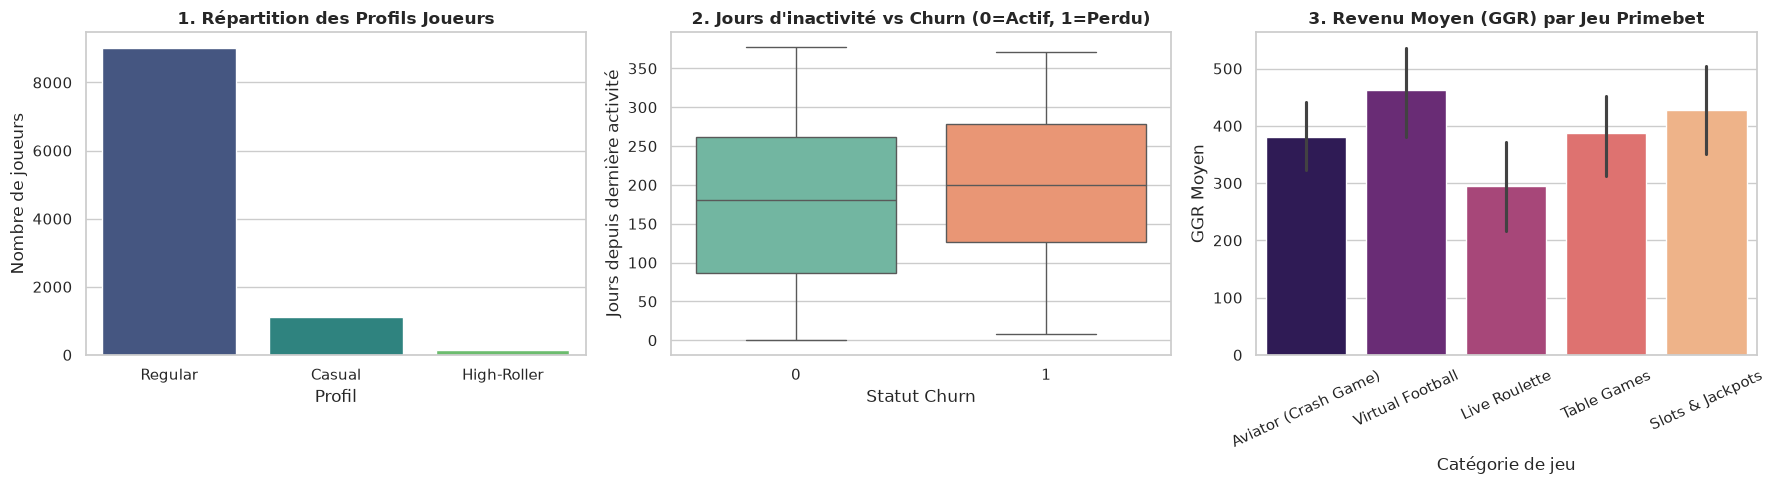

Dataset propre sauvegardé avec succès (10300 lignes, 38 colonnes) -> primebet_players_clean.csv


<Figure size 640x480 with 0 Axes>

In [73]:
import os

# Configuration visuelle propre
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graphique 1 : Répartition des profils de joueurs
sns.countplot(
    data=df_clean, 
    x='betting_profile', 
    order=df_clean['betting_profile'].value_counts().index,
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title("1. Répartition des Profils Joueurs", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Profil")
axes[0].set_ylabel("Nombre de joueurs")

# Graphique 2 : Inactivité (jours) vs Abandon (Churn)
sns.boxplot(
    data=df_clean, 
    x='churn', 
    y='days_since_last_activity', 
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title("2. Jours d'inactivité vs Churn (0=Actif, 1=Perdu)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Statut Churn")
axes[1].set_ylabel("Jours depuis dernière activité")

# Graphique 3 : Revenu Brut (GGR) moyen par type de jeu
sns.barplot(
    data=df_clean, 
    x='game_genre_preference', 
    y='total_ggr', 
    palette='magma',
    ax=axes[2]
)
axes[2].set_title("3. Revenu Moyen (GGR) par Jeu Primebet", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Catégorie de jeu")
axes[2].set_ylabel("GGR Moyen")
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

# Exportons les visualisations dans un dossier dédié
output_dir = Path('../data/visualizations')
output_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(output_dir / 'primebet_visualizations.png')

# Sauvegarde du dataset propre prêt pour le Machine Learning
output_path = 'primebet_players_clean.csv'
df_clean.to_csv(output_path, index=False)
print(f"Dataset propre sauvegardé avec succès ({df_clean.shape[0]} lignes, {df_clean.shape[1]} colonnes) -> {output_path}")